In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/abdullah687/oaizib-cm/HF-OAIZIB-CM.png
/kaggle/input/datasets/abdullah687/oaizib-cm/README.md
/kaggle/input/datasets/abdullah687/oaizib-cm/gitattributes
/kaggle/input/datasets/abdullah687/oaizib-cm/imagesTr/imagesTr/oaizib_001_0000.nii
/kaggle/input/datasets/abdullah687/oaizib-cm/imagesTr/imagesTr/oaizib_002_0000.nii
/kaggle/input/datasets/abdullah687/oaizib-cm/imagesTr/imagesTr/oaizib_003_0000.nii
/kaggle/input/datasets/abdullah687/oaizib-cm/imagesTr/imagesTr/oaizib_004_0000.nii
/kaggle/input/datasets/abdullah687/oaizib-cm/imagesTr/imagesTr/oaizib_005_0000.nii
/kaggle/input/datasets/abdullah687/oaizib-cm/imagesTr/imagesTr/oaizib_006_0000.nii
/kaggle/input/datasets/abdullah687/oaizib-cm/imagesTr/imagesTr/oaizib_007_0000.nii
/kaggle/input/datasets/abdullah687/oaizib-cm/imagesTr/imagesTr/oaizib_008_0000.nii
/kaggle/input/datasets/abdullah687/oaizib-cm/imagesTr/imagesTr/oaizib_009_0000.nii
/kaggle/input/datasets/abdullah687/oaizib-cm/imagesTr/imagesTr/oaizib_010_000

Inspect dataset structure

In [2]:
import os

DATASET_ROOT = "/kaggle/input"

for root, dirs, files in os.walk(DATASET_ROOT):
    level = root.replace(DATASET_ROOT, "").count(os.sep)

    if level > 2:
        dirs[:] = []
        continue

    print("  " * level + os.path.basename(root) + "/")

    for file in files[:5]:
        print("  " * (level + 1) + file)

input/
  datasets/
    abdullah687/


In [3]:
!pip install -q nibabel pandas numpy openpyxl

Locate your dataset folders

In [4]:
import os

for root, dirs, files in os.walk(DATASET_ROOT):
    for folder in ["imagesTr", "labelsTr", "imagesTs", "labelsTs"]:
        if folder in dirs:
            print(folder, ":", os.path.join(root, folder))

imagesTr : /kaggle/input/datasets/abdullah687/oaizib-cm/imagesTr
labelsTr : /kaggle/input/datasets/abdullah687/oaizib-cm/labelsTr
imagesTs : /kaggle/input/datasets/abdullah687/oaizib-cm/imagesTs
labelsTs : /kaggle/input/datasets/abdullah687/oaizib-cm/labelsTs
imagesTr : /kaggle/input/datasets/abdullah687/oaizib-cm/imagesTr/imagesTr
imagesTs : /kaggle/input/datasets/abdullah687/oaizib-cm/imagesTs/imagesTs
labelsTr : /kaggle/input/datasets/abdullah687/oaizib-cm/labelsTr/labelsTr
labelsTs : /kaggle/input/datasets/abdullah687/oaizib-cm/labelsTs/labelsTs


# Configure dataset paths

In [5]:
from pathlib import Path

DATASET_ROOT = Path("/kaggle/input/datasets/abdullah687/oaizib-cm")

IMAGE_TRAIN = DATASET_ROOT / "imagesTr" / "imagesTr"
IMAGE_TEST  = DATASET_ROOT / "imagesTs" / "imagesTs"

LABEL_TRAIN = DATASET_ROOT / "labelsTr" / "labelsTr"
LABEL_TEST  = DATASET_ROOT / "labelsTs" / "labelsTs"

INFO_DIR = DATASET_ROOT / "info"
ATLAS_DIR = DATASET_ROOT / "template_atlas"

print("Dataset exists:", DATASET_ROOT.exists())

Dataset exists: True


# Verify folder structure

In [6]:
folders = {
    "Training MRI": IMAGE_TRAIN,
    "Testing MRI": IMAGE_TEST,
    "Training Masks": LABEL_TRAIN,
    "Testing Masks": LABEL_TEST,
    "Information": INFO_DIR,
    "Template Atlas": ATLAS_DIR
}

for name, path in folders.items():
    print(f"\n{name}")
    print("Path:", path)
    print("Exists:", path.exists())

    if path.exists():
        print("Contents:", [p.name for p in list(path.iterdir())[:5]])


Training MRI
Path: /kaggle/input/datasets/abdullah687/oaizib-cm/imagesTr/imagesTr
Exists: True
Contents: ['oaizib_001_0000.nii', 'oaizib_002_0000.nii', 'oaizib_003_0000.nii', 'oaizib_004_0000.nii', 'oaizib_005_0000.nii']

Testing MRI
Path: /kaggle/input/datasets/abdullah687/oaizib-cm/imagesTs/imagesTs
Exists: True
Contents: ['oaizib_405_0000.nii', 'oaizib_406_0000.nii', 'oaizib_407_0000.nii', 'oaizib_408_0000.nii', 'oaizib_409_0000.nii']

Training Masks
Path: /kaggle/input/datasets/abdullah687/oaizib-cm/labelsTr/labelsTr
Exists: True
Contents: ['oaizib_001.nii', 'oaizib_002.nii', 'oaizib_003.nii', 'oaizib_004.nii', 'oaizib_005.nii']

Testing Masks
Path: /kaggle/input/datasets/abdullah687/oaizib-cm/labelsTs/labelsTs
Exists: True
Contents: ['oaizib_405.nii', 'oaizib_406.nii', 'oaizib_407.nii', 'oaizib_408.nii', 'oaizib_409.nii']

Information
Path: /kaggle/input/datasets/abdullah687/oaizib-cm/info
Exists: True
Contents: ['info']

Template Atlas
Path: /kaggle/input/datasets/abdullah687/oa

# Count NIfTI files

In [7]:
def get_nifti_files(folder):
    return sorted([
        p for p in folder.iterdir()
        if p.is_file() and (
            p.name.endswith(".nii") or
            p.name.endswith(".nii.gz")
        )
    ])

file_groups = {
    "Training MRI": IMAGE_TRAIN,
    "Training Masks": LABEL_TRAIN,
    "Testing MRI": IMAGE_TEST,
    "Testing Masks": LABEL_TEST
}

expected_counts = {
    "Training MRI": 404,
    "Training Masks": 404,
    "Testing MRI": 103,
    "Testing Masks": 103
}

for name, folder in file_groups.items():
    files = get_nifti_files(folder)
    expected = expected_counts[name]

    print(f"{name}: {len(files)}/{expected}",
          "PASS" if len(files) == expected else "CHECK")

Training MRI: 404/404 PASS
Training Masks: 404/404 PASS
Testing MRI: 103/103 PASS
Testing Masks: 103/103 PASS


# Inspect filenames

In [8]:
for name, folder in file_groups.items():
    files = get_nifti_files(folder)

    print(f"\n{name}")
    for file in files[:5]:
        print(file.name)


Training MRI
oaizib_001_0000.nii
oaizib_002_0000.nii
oaizib_003_0000.nii
oaizib_004_0000.nii
oaizib_005_0000.nii

Training Masks
oaizib_001.nii
oaizib_002.nii
oaizib_003.nii
oaizib_004.nii
oaizib_005.nii

Testing MRI
oaizib_405_0000.nii
oaizib_406_0000.nii
oaizib_407_0000.nii
oaizib_408_0000.nii
oaizib_409_0000.nii

Testing Masks
oaizib_405.nii
oaizib_406.nii
oaizib_407.nii
oaizib_408.nii
oaizib_409.nii


In [9]:
!pip install -q nibabel pandas numpy scipy

# Install and import audit libraries

In [10]:
!pip install -q nibabel pandas numpy

import nibabel as nib
import numpy as np
import pandas as pd
import re
from pathlib import Path

print("Libraries imported successfully.")

Libraries imported successfully.


# Match every MRI with its mask#

In [11]:
def extract_case_id(filename):
    match = re.search(r"oaizib_(\d+)", filename)
    return match.group(1) if match else None


def create_file_map(folder, is_image=False):
    result = {}

    for file in folder.iterdir():
        if not file.name.endswith((".nii", ".nii.gz")):
            continue

        case_id = extract_case_id(file.name)

        if case_id is None:
            continue

        if case_id in result:
            raise ValueError(f"Duplicate case ID {case_id} in {folder}")

        result[case_id] = file

    return result


splits = {
    "train": (IMAGE_TRAIN, LABEL_TRAIN),
    "test": (IMAGE_TEST, LABEL_TEST)
}

for split, (image_dir, label_dir) in splits.items():

    images = create_file_map(image_dir, True)
    masks = create_file_map(label_dir)

    missing_masks = sorted(set(images) - set(masks))
    missing_images = sorted(set(masks) - set(images))

    print(f"\n{split.upper()} SPLIT")
    print("MRI files:", len(images))
    print("Mask files:", len(masks))
    print("Missing masks:", missing_masks)
    print("Missing MRIs:", missing_images)
    print("Matching pairs:", len(set(images) & set(masks)))


TRAIN SPLIT
MRI files: 404
Mask files: 404
Missing masks: []
Missing MRIs: []
Matching pairs: 404

TEST SPLIT
MRI files: 103
Mask files: 103
Missing masks: []
Missing MRIs: []
Matching pairs: 103


# **Full NIfTI quality audit**

In [12]:
LABEL_NAMES = {
    0: "Background",
    1: "Femur",
    2: "Femoral Cartilage",
    3: "Tibia",
    4: "Medial Tibial Cartilage",
    5: "Lateral Tibial Cartilage"
}

audit_results = []

for split, (image_dir, label_dir) in splits.items():

    images = create_file_map(image_dir, True)
    masks = create_file_map(label_dir)

    for case_id in sorted(set(images) & set(masks)):

        image_path = images[case_id]
        mask_path = masks[case_id]

        row = {
            "split": split,
            "case_id": case_id,
            "image_file": image_path.name,
            "mask_file": mask_path.name,
            "image_readable": False,
            "mask_readable": False,
            "shape_match": False,
            "spacing_match": False,
            "affine_match": False,
            "orientation_match": False,
            "finite_image": False,
            "integer_mask": False,
            "valid_labels": False,
            "labels_found": "",
            "voxel_spacing": "",
            "orientation": "",
            "image_shape": "",
            "mask_shape": "",
            "error": ""
        }

        try:
            image = nib.load(str(image_path))
            row["image_readable"] = True

            mask = nib.load(str(mask_path))
            row["mask_readable"] = True

            image_shape = image.shape
            mask_shape = mask.shape

            row["image_shape"] = str(image_shape)
            row["mask_shape"] = str(mask_shape)

            row["shape_match"] = image_shape == mask_shape

            image_spacing = np.array(image.header.get_zooms()[:3])
            mask_spacing = np.array(mask.header.get_zooms()[:3])

            row["spacing_match"] = np.allclose(
                image_spacing, mask_spacing, atol=1e-4
            )

            row["voxel_spacing"] = str(
                np.round(image_spacing, 5).tolist()
            )

            row["affine_match"] = np.allclose(
                image.affine, mask.affine, atol=1e-4
            )

            image_orientation = nib.aff2axcodes(image.affine)
            mask_orientation = nib.aff2axcodes(mask.affine)

            row["orientation"] = str(image_orientation)

            row["orientation_match"] = (
                image_orientation == mask_orientation
            )

            image_data = image.get_fdata(dtype=np.float32)
            mask_data = np.asanyarray(mask.dataobj)

            row["finite_image"] = bool(
                np.isfinite(image_data).all()
            )

            row["integer_mask"] = bool(
                np.all(np.isfinite(mask_data))
                and np.allclose(mask_data, np.round(mask_data))
            )

            unique_labels = np.unique(mask_data)

            row["labels_found"] = str(
                unique_labels.tolist()
            )

            row["valid_labels"] = bool(
                np.all(np.isin(unique_labels, list(LABEL_NAMES)))
            )

            del image_data, mask_data, image, mask

        except Exception as e:
            row["error"] = str(e)

        audit_results.append(row)

    print(f"Completed {split} split.")

audit_df = pd.DataFrame(audit_results)

print("\nTotal audited cases:", len(audit_df))
print("Audit completed.")

Completed train split.
Completed test split.

Total audited cases: 507
Audit completed.


# Review audit results

In [13]:
check_columns = [
    "image_readable",
    "mask_readable",
    "shape_match",
    "spacing_match",
    "affine_match",
    "orientation_match",
    "finite_image",
    "integer_mask",
    "valid_labels"
]

print("CHECK RESULTS\n")

for column in check_columns:
    passed = int(audit_df[column].sum())
    total = len(audit_df)

    print(f"{column}: {passed}/{total} PASS")

print("\nCases with at least one failed check:")

failed = audit_df[~audit_df[check_columns].all(axis=1)]

display(failed[
    ["split", "case_id", *check_columns, "error"]
])

CHECK RESULTS

image_readable: 507/507 PASS
mask_readable: 507/507 PASS
shape_match: 507/507 PASS
spacing_match: 507/507 PASS
affine_match: 507/507 PASS
orientation_match: 507/507 PASS
finite_image: 507/507 PASS
integer_mask: 507/507 PASS
valid_labels: 507/507 PASS

Cases with at least one failed check:


,split,case_id,image_readable,mask_readable,shape_match,spacing_match,affine_match,orientation_match,finite_image,integer_mask,valid_labels,error


# Inspect segmentation label distribution

In [14]:
label_counts = []

for split, (_, label_dir) in splits.items():

    masks = create_file_map(label_dir)

    for case_id, mask_path in sorted(masks.items()):

        mask = nib.load(str(mask_path))
        data = np.asanyarray(mask.dataobj)

        labels, counts = np.unique(data, return_counts=True)

        row = {
            "split": split,
            "case_id": case_id
        }

        for label_id, label_name in LABEL_NAMES.items():
            count = counts[labels == label_id].sum()
            row[label_name] = int(count)

        label_counts.append(row)

label_df = pd.DataFrame(label_counts)

display(label_df.head())

print("\nTotal voxels per class:")

display(
    label_df.groupby("split")[list(LABEL_NAMES.values())].sum()
)

,split,case_id,Background,Femur,Femoral Cartilage,Tibia,Medial Tibial Cartilage,Lateral Tibial Cartilage
0,train,001,19610098,2158042,198528,1569406,26057,30829
1,train,002,20424948,1802824,133161,1190317,18258,23452
2,train,003,20116137,1996246,149808,1285138,20451,25180
3,train,004,20652303,1678157,137676,1086058,20122,18644
4,train,005,20977911,1437646,103794,1039315,14757,19537



Total voxels per class:


,Background,Femur,Femoral Cartilage,Tibia,Medial Tibial Cartilage,Lateral Tibial Cartilage
split,,,,,,
test,2084172832,193802842,16143174,131264039,2232353,2459640
train,8089397423,815590303,66429645,540995208,8912785,10230476


# Check case 454

In [15]:
case_454 = audit_df[audit_df["case_id"] == "454"]

display(case_454.T)

,453
split,test
case_id,454
image_file,oaizib_454_0000.nii
mask_file,oaizib_454.nii
image_readable,True
mask_readable,True
shape_match,True
spacing_match,True
affine_match,True
orientation_match,True


# Save audit reports

In [16]:
OUTPUT_DIR = Path("/kaggle/working/kneevision_audit")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

audit_df.to_csv(
    OUTPUT_DIR / "nifti_quality_audit.csv",
    index=False
)

label_df.to_csv(
    OUTPUT_DIR / "segmentation_label_distribution.csv",
    index=False
)

print("Reports saved to:", OUTPUT_DIR)

Reports saved to: /kaggle/working/kneevision_audit


# Per-case class distribution

In [17]:
import numpy as np
import pandas as pd

LABEL_NAMES = {
    0: "Background",
    1: "Femur",
    2: "Femoral_Cartilage",
    3: "Tibia",
    4: "Medial_Tibial_Cartilage",
    5: "Lateral_Tibial_Cartilage"
}

case_results = []

for split, (_, label_dir) in splits.items():

    masks = create_file_map(label_dir)

    for case_id, mask_path in sorted(masks.items()):

        mask = nib.load(str(mask_path))
        data = np.asanyarray(mask.dataobj)

        labels, counts = np.unique(data, return_counts=True)
        count_map = dict(zip(labels.astype(int), counts))

        row = {
            "split": split,
            "case_id": case_id
        }

        for label_id, name in LABEL_NAMES.items():
            row[name] = int(count_map.get(label_id, 0))

        case_results.append(row)

case_df = pd.DataFrame(case_results)

class_columns = list(LABEL_NAMES.values())[1:]

print("Total cases:", len(case_df))

for column in class_columns:
    missing = case_df[case_df[column] == 0]

    print(f"{column}:")
    print("  Cases with class:", len(case_df) - len(missing))
    print("  Cases without class:", len(missing))

display(case_df.head())

Total cases: 507
Femur:
  Cases with class: 507
  Cases without class: 0
Femoral_Cartilage:
  Cases with class: 507
  Cases without class: 0
Tibia:
  Cases with class: 507
  Cases without class: 0
Medial_Tibial_Cartilage:
  Cases with class: 507
  Cases without class: 0
Lateral_Tibial_Cartilage:
  Cases with class: 507
  Cases without class: 0


,split,case_id,Background,Femur,Femoral_Cartilage,Tibia,Medial_Tibial_Cartilage,Lateral_Tibial_Cartilage
0,train,001,19610098,2158042,198528,1569406,26057,30829
1,train,002,20424948,1802824,133161,1190317,18258,23452
2,train,003,20116137,1996246,149808,1285138,20451,25180
3,train,004,20652303,1678157,137676,1086058,20122,18644
4,train,005,20977911,1437646,103794,1039315,14757,19537


# Save the results

In [18]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

case_df.to_csv(
    OUTPUT_DIR / "per_case_class_distribution.csv",
    index=False
)

print("Saved per-case class distribution.")

Saved per-case class distribution.


# Visually inspect MRI and segmentation

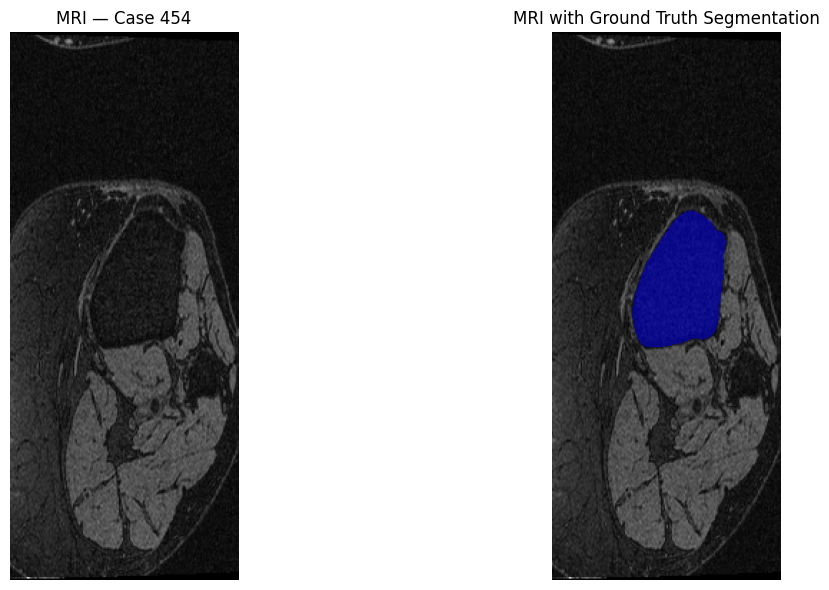

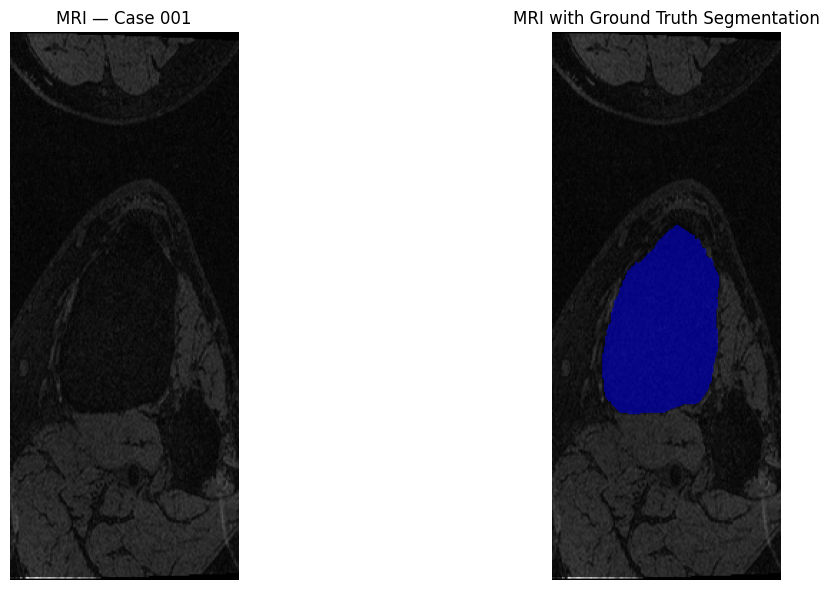

In [19]:
import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np

def visualize_case(case_id, split="test", slice_index=80):

    image_dir, label_dir = splits[split]

    images = create_file_map(image_dir, True)
    masks = create_file_map(label_dir)

    image = nib.load(str(images[case_id])).get_fdata()
    mask = nib.load(str(masks[case_id])).get_fdata()

    if slice_index >= image.shape[2]:
        slice_index = image.shape[2] // 2

    colors = {
        1: "red",
        2: "lime",
        3: "blue",
        4: "yellow",
        5: "magenta"
    }

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    axes[0].imshow(image[:, :, slice_index].T, cmap="gray", origin="lower")
    axes[0].set_title(f"MRI — Case {case_id}")

    axes[1].imshow(image[:, :, slice_index].T, cmap="gray", origin="lower")

    for label, color in colors.items():
        overlay = np.ma.masked_where(
            mask[:, :, slice_index].T != label,
            mask[:, :, slice_index].T
        )
        axes[1].imshow(
            overlay,
            cmap=plt.matplotlib.colors.ListedColormap([color]),
            alpha=0.5,
            origin="lower"
        )

    axes[1].set_title("MRI with Ground Truth Segmentation")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

visualize_case("454", split="test", slice_index=80)
visualize_case("001", split="train", slice_index=80)